In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# import time
# import copy
import gc
import math

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [4]:
n_samples = 32
# n_samples = 128
# n_samples = 1

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


# Architecture

## Functions

In [5]:
def freeze_all_but_gates(model):
    for p in model.parameters():
        p.requires_grad = False
    for layer in model.model.layers:
        for p in layer.mlp.gate.parameters():   # TokenGate parameters
            p.requires_grad = True

def get_gate_params(model):
    params = []
    for layer in model.model.layers:
        params += list(layer.mlp.gate.parameters())
    return params

def set_init_gate_weights(model, p_keep=0.7):
    init = torch.log(torch.tensor(p_keep / (1 - p_keep)))
    for layer in model.model.layers:
        gate = layer.mlp.gate
        gate.logits = nn.Parameter(init + 1 * torch.randn_like(gate.logits, dtype=torch.bfloat16))
        # self.logits = nn.Parameter(init * torch.ones(1, T, 1, dtype=torch.bfloat16))
        # self.logits = nn.Parameter(torch.zeros(1, T, 1, dtype=torch.bfloat16))  # learnable per-token gate
        

In [6]:
def gated_loss(lm_loss, gate_store,
               target_skip=0.3, lambda_ratio=1.0, lambda_bin=1.0):
    # concatenate all gates -> [B*T*L]
    g = torch.cat([gi.reshape(-1) for gi in gate_store], dim=0)
    skip_ratio = (1.0 - g).mean()

    # ratio loss (keep skip near target)
    ratio_loss = (skip_ratio - target_skip) ** 2

    # binarization loss (push gates to 0 or 1)
    bin_loss = (g * (1.0 - g)).mean()

    total_loss = lm_loss + lambda_ratio * ratio_loss + lambda_bin * bin_loss

    return total_loss, {
        "skip_ratio": skip_ratio.detach(),
        "ratio_loss": ratio_loss.detach(),
        "bin_loss": bin_loss.detach(),
    }

In [7]:
def add_gates(model, gate_store, noise_scale=0.0, tau=1.0):
    for layer in model.model.layers:
        d_model = layer.mlp.gate_proj.in_features
        layer.mlp = GatedMLP(layer.mlp, d_model, gate_store, noise_scale=noise_scale, tau=tau)

def set_noise(model, noise_scale=0.0):
    for layer in model.model.layers:
        layer.mlp.gate.noise_scale = noise_scale

def set_tau(model, tau=1.0):
    for layer in model.model.layers:
        layer.mlp.gate.tau = tau

In [8]:
def visualize_gate_heatmap(gate_store):
    """
    gate_store: list of tensors [1, T, 1], one per layer
    """

    # Shape: [L, T]
    mat = torch.stack([g.squeeze() for g in gate_store], dim=0)
    mat = mat.detach().cpu().float().numpy()

    plt.figure(figsize=(12, 6))
    plt.imshow(mat, aspect="auto")
    plt.colorbar(label="Gate value")
    plt.xlabel("Token index")
    plt.ylabel("Layer index")
    plt.title("Gate heatmap (layers × tokens)")
    plt.show()


## Classes

In [9]:
sample_length = 8192

class TokenGate(nn.Module):
    def __init__(self, T, noise_scale=0.0, tau=1.0, p_keep=0.7):
        super().__init__()
        self.logits = nn.Parameter(torch.zeros(1, T, 1, dtype=torch.bfloat16))
        self.noise_scale = noise_scale
        self.tau = tau

    def forward(self, h):
        B = h.shape[0]

        logits = self.logits.expand(B, -1, -1)  # [B, T, 1]

        if self.training and self.noise_scale > 0:
            u = torch.rand_like(logits).clamp(1e-6, 1 - 1e-6)
            noise = torch.log(u) - torch.log(1 - u)
            logits = logits + self.noise_scale * noise
        
        gate = torch.sigmoid(logits / self.tau)
        if not self.training:
            gate = gate.round()
        
        return gate  # [B, T, 1]

class GatedMLP(nn.Module):
    def __init__(self, mlp: nn.Module, d_model: int, gate_store: list,  noise_scale=0.0, tau=1.0):
        super().__init__()
        self.mlp = mlp
        self.gate = TokenGate(sample_length, noise_scale=noise_scale, tau=tau)
        self.gate_store = gate_store      # to collect gates for loss

    def forward(self, h):
        g = self.gate(h)                  # [B, T, 1]
        self.gate_store.append(g)

        mlp_out = self.mlp(h)             # [B, T, D]
        return g * mlp_out
        # return mlp_out

# Training

In [10]:
def train_gates(model, dataloader, gate_store, stats, device="cuda",
                epochs=1, lr=1e-3, tau_min=0.4, sigma_max=0.5,
                target_skip=0.30, lambda_ratio=1.0, lambda_bin=1.0,
                grad_accum_steps=1, max_grad_norm=1.0, 
                verbose=False, log_every=50):
    
    T = epochs * len(dataloader)     # total steps = 256

    # optimizer on gate params only
    gate_params = get_gate_params(model)
    optimizer = torch.optim.AdamW(gate_params, lr=lr)
    # scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.999)
    scheduler = torch.optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=1.0,
        end_factor=1e-2,
        total_iters=T,
    )
    
    global_step = 0
    for epoch in range(epochs):
        for step, batch in enumerate(dataloader):
            global_step += 1
            gate_store.clear()

            input_ids, labels = batch
            batch = {"input_ids": input_ids.to(device), "labels": labels.to(device)}

            ##
            t = global_step / (T - 1)          # goes 0 -> 1
            
            tau = max(tau_min, 1.0 - (1.0 - tau_min) * (t / 0.8))
            sigma = sigma_max * max(0.0, 1.0 - t/0.7)     # sigma_max -> 0 by 70% of training
            
            set_tau(model, tau)
            set_noise(model, sigma)
                        
            ##
            
            outputs = model(**batch)
            
            lm_loss = torch.exp(outputs.loss)
            loss, loss_info = gated_loss(lm_loss, gate_store, lambda_ratio=lambda_ratio, lambda_bin=lambda_bin, target_skip=target_skip)
            loss = loss / grad_accum_steps
            loss.backward()

            if global_step % grad_accum_steps == 0:
                if max_grad_norm is not None:
                    torch.nn.utils.clip_grad_norm_(gate_params, max_grad_norm)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            # logging
            if global_step % log_every == 0:
                with torch.no_grad():
                    # ppl = torch.exp(lm_loss.detach()).item()
                    ppl = lm_loss.detach().item()
                    lr = optimizer.param_groups[0]["lr"]
                    total_loss = lm_loss + lambda_ratio*loss_info['ratio_loss'] + lambda_bin*loss_info['bin_loss']
                    if verbose:
                        print(
                            f"epoch {epoch} lr {lr:.1e} tau {tau:.2f} sigma {sigma:.2f} | "
                            f"lm_loss={lm_loss.item():.2f} | "
                            f"ppl={ppl:6.2f} | "
                            f"skip_ratio={loss_info['skip_ratio'].item():.2f} | "
                            f"ratio_loss={(lambda_ratio*loss_info['ratio_loss']).item():.2f} | "
                            f"bin_loss={(lambda_bin*loss_info['bin_loss']).item():.2f} | "
                            f"total_loss={total_loss.item():.2f}"
                        )
                    stats['ppl'].append(ppl)
                    stats['skip_ratio'].append(loss_info['skip_ratio'].item())
                    stats['ratio_loss'].append((lambda_ratio*loss_info['ratio_loss']).item())
                    stats['bin_loss'].append((lambda_bin*loss_info['bin_loss']).item())
                    stats['total_loss'].append(total_loss.item())

    return model, stats

In [11]:
model = get_opt(model_name)
gate_store = []
add_gates(model, gate_store=gate_store)#, noise_scale=0.3, tau=0.3)
model.to(DEV)
model.train();

In [12]:
stats = {'ppl': [], 'val_ppl': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

set_init_gate_weights(model, p_keep=0.65)
freeze_all_but_gates(model)

model, stats = train_gates(
    model=model,
    dataloader=dataloader[10:11],
    gate_store=gate_store,
    stats=stats,
    device=DEV,
    epochs=20,
    lr=1e-2,
    tau_min=0.2,
    sigma_max=0.3,
    target_skip=0.30,
    lambda_ratio=1e2,
    lambda_bin=1e2,
    grad_accum_steps=1,
    log_every=1,
    verbose=True
)
# model.eval();

epoch 0 lr 9.5e-03 tau 0.95 sigma 0.28 | lm_loss=9.40 | ppl=  9.40 | skip_ratio=0.38 | ratio_loss=0.59 | bin_loss=18.50 | total_loss=28.49
epoch 1 lr 9.0e-03 tau 0.89 sigma 0.25 | lm_loss=4.86 | ppl=  4.86 | skip_ratio=0.37 | ratio_loss=0.51 | bin_loss=18.12 | total_loss=23.49
epoch 2 lr 8.5e-03 tau 0.84 sigma 0.23 | lm_loss=2.24 | ppl=  2.24 | skip_ratio=0.37 | ratio_loss=0.43 | bin_loss=17.62 | total_loss=20.30
epoch 3 lr 8.0e-03 tau 0.79 sigma 0.21 | lm_loss=1.66 | ppl=  1.66 | skip_ratio=0.36 | ratio_loss=0.35 | bin_loss=17.25 | total_loss=19.26
epoch 4 lr 7.5e-03 tau 0.74 sigma 0.19 | lm_loss=3.23 | ppl=  3.23 | skip_ratio=0.35 | ratio_loss=0.29 | bin_loss=16.62 | total_loss=20.14
epoch 5 lr 7.0e-03 tau 0.68 sigma 0.16 | lm_loss=1.67 | ppl=  1.67 | skip_ratio=0.35 | ratio_loss=0.21 | bin_loss=16.00 | total_loss=17.88
epoch 6 lr 6.5e-03 tau 0.63 sigma 0.14 | lm_loss=1.69 | ppl=  1.69 | skip_ratio=0.34 | ratio_loss=0.14 | bin_loss=15.31 | total_loss=17.14
epoch 7 lr 6.0e-03 tau 0.58

## Training stats

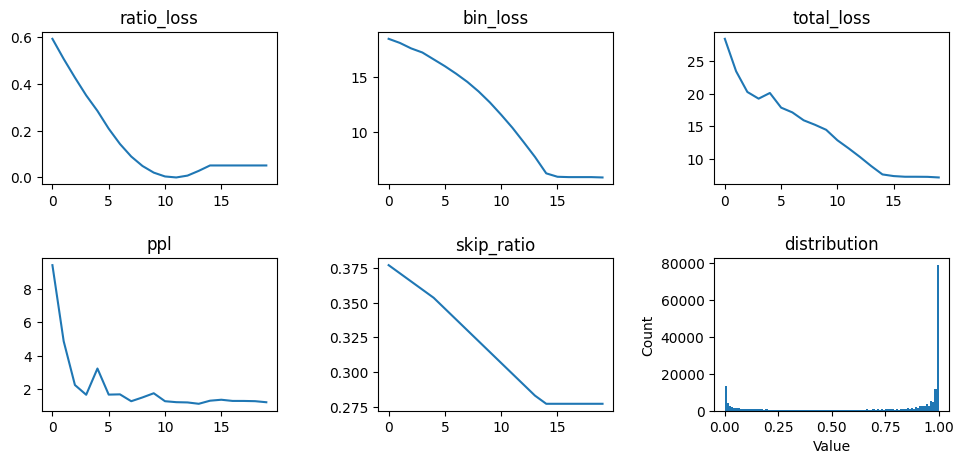

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(10, 5))
for i, x in enumerate(['ratio_loss', 'bin_loss', 'total_loss', 'ppl', 'skip_ratio', 'distribution']):
    r, c = divmod(i, 3)
    if x == 'distribution':
        flat = torch.cat([t.reshape(-1) for t in gate_store[-24:]])
        values = flat.float().detach().cpu().numpy()
        ax[r, c].hist(values, bins=100)
        ax[r, c].set_xlabel("Value")
        ax[r, c].set_ylabel("Count")
        ax[r, c].set_title(x)
        continue
    ax[r, c].plot(stats[x])
    ax[r, c].set_title(x)
    if x == 'ppl': 
        ax[r, c].plot(stats['val_ppl'])
        # ax[r, c].set_ylim((-1e2, 1e3))
fig.tight_layout(pad=2)

## Decision visualization

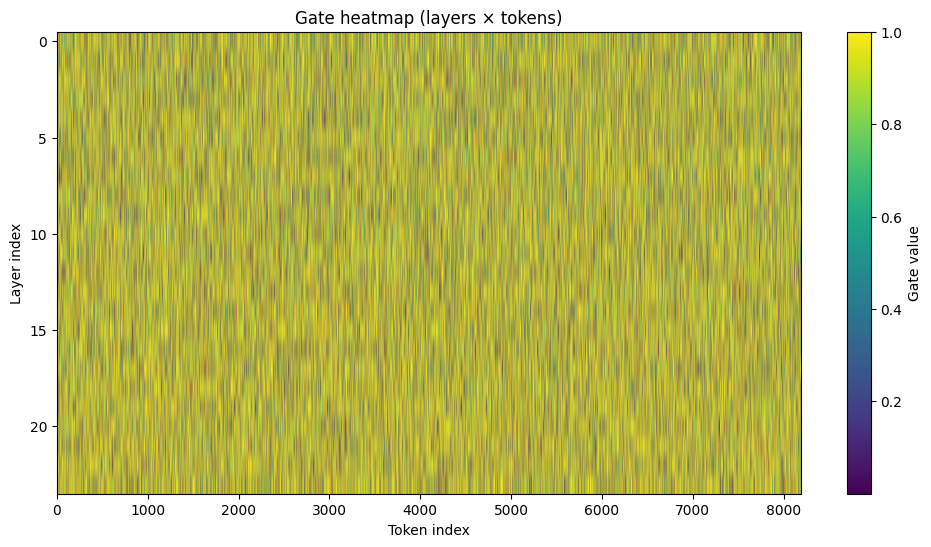

In [14]:
# decisions on training data
visualize_gate_heatmap(gate_store[:24])

In [15]:
batch = dataloader[10]
input_ids, labels = batch
batch = {"input_ids": input_ids.to(DEV), "labels": labels.to(DEV)}

outputs = model(**batch)
torch.exp(outputs.loss).item()

1.2201502323150635

# Different approach

## Architecture

In [6]:
class TokenGate(nn.Module):
    def __init__(self, d_model, tau=1.0, gamma=-0.1, zeta=1.1):
        super().__init__()
        self.proj = nn.Linear(d_model, 1, dtype=torch.bfloat16)
        self.tau = tau
        self.gamma = gamma
        self.zeta = zeta

    def forward(self, h):
        log_alpha = self.proj(h)            # [B, T, 1]

        if self.training:
            u = torch.rand_like(log_alpha).clamp_(1e-6, 1 - 1e-6)
            noise = torch.log(u) - torch.log1p(-u)  # logistic noise
            s = torch.sigmoid((log_alpha + noise) / self.tau)
        else:
            # deterministic proxy at eval
            s = torch.sigmoid(log_alpha)

        # hard-concrete stretch + clip
        s_bar = s * (self.zeta - self.gamma) + self.gamma
        z = torch.clamp(s_bar, 0.0, 1.0)     # <-- this makes it 0/1 often

        return z, log_alpha

In [7]:
class GatedMLP(nn.Module):
    def __init__(self, mlp: nn.Module, d_model: int, gate_store: list, tau=1.0, gamma=-0.1, zeta=1.1):
        super().__init__()
        self.mlp = mlp
        self.gate = TokenGate(d_model, tau=tau, gamma=gamma, zeta=zeta)
        self.gate_store = gate_store  # store per-layer tensors for loss

    def forward(self, h):
        z, log_alpha = self.gate(h)   # z: [B,T,1]  log_alpha: [B,T,1]

        self.gate_store.append((z, log_alpha))

        mlp_out = self.mlp(h)         # [B,T,D]
        return z * mlp_out            # gated MLP output


In [8]:
def p_nonzero_from_log_alpha(log_alpha, tau, gamma=-0.1, zeta=1.1):
    t = (0.0 - gamma) / (zeta - gamma)               # in (0,1)
    logit_t = math.log(t) - math.log(1.0 - t)
    return torch.sigmoid(log_alpha - tau * logit_t)  # P(z > 0)

def gate_losses(gate_store, tau, target_skip=0.30, w_bin=0.5, gamma=-0.1, zeta=1.1):
    # gate_store = list of (z, log_alpha) from all layers
    zs, las = zip(*gate_store)  # tuples of tensors

    # expected keep prob -> expected skip ratio
    p = torch.cat([p_nonzero_from_log_alpha(la, tau, gamma, zeta).reshape(-1) for la in las], dim=0)
    skip = 1.0 - p.mean()
    loss_ratio = (skip - target_skip).abs()

    loss_bin = (p * (1.0 - p)).mean()

    return loss_ratio, loss_bin, skip


In [9]:
def add_gates(model, gate_store, tau=1.0, gamma=-0.1, zeta=1.1):
    for layer in model.model.layers:
        d_model = layer.mlp.gate_proj.in_features
        layer.mlp = GatedMLP(layer.mlp, d_model, gate_store, tau=tau, gamma=gamma, zeta=zeta)

def set_tau_all_gates(model, tau):
    for layer in model.model.layers:
        layer.mlp.gate.tau = float(tau)

def tau_linear(step, total_steps, start=1.0, end=0.3, frac=0.70):
    ramp = max(1, int(total_steps * frac))
    if step >= ramp:
        return end
    r = step / ramp
    return start + (end - start) * r


In [10]:
def freeze_all_but_gates(model):
    for p in model.parameters():
        p.requires_grad = False
    for layer in model.model.layers:
        for p in layer.mlp.gate.parameters():   # TokenGate parameters
            p.requires_grad = True

def get_gate_params(model):
    params = []
    for layer in model.model.layers:
        params += list(layer.mlp.gate.parameters())
    return params

def set_init_gate_weights(model, init_keep=0.7):
    init_logit = math.log(init_keep / (1 - init_keep))

    for layer in model.model.layers:
        # initialization
        gate = layer.mlp.gate.proj
        # gate.weight.data.zero_()
        gate.bias.data.fill_(init_logit)
        gate.weight.data.normal_(0.0, 1e-1)
        # gate.bias.data.zero_()
        

In [11]:
def train_gates(model, dataloader, gate_store, stats, device="cuda",
                epochs=1, lr=1e-3,
                target_skip=0.30, w_ratio=5.0, w_bin=0.5,
                verbose=False, log_every=50, eval_val_ppl=True):
    T = epochs * len(dataloader)     # total steps = 256

    gate_params = get_gate_params(model)
    optimizer = torch.optim.AdamW(gate_params, lr=lr)
    # scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.999)
    scheduler = torch.optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=1.0,
        end_factor=0.1,
        total_iters=T,
    )
    
    global_step = 0
    for epoch in range(epochs):
        for step, batch in enumerate(dataloader, start=1):
            global_step += 1
            gate_store.clear()
        
            tau = tau_linear(step, T, start=1.0, end=0.3, frac=0.70)
            set_tau_all_gates(model, tau)
            
            input_ids, labels = batch
            batch = {"input_ids": input_ids.to(device), "labels": labels.to(device)}
            out = model(**batch)
            
            lm_loss = out.loss
            loss_ratio, loss_bin, skip = gate_losses(gate_store, tau, target_skip=0.30, w_bin=0.5)
            loss = lm_loss + w_ratio * loss_ratio + w_bin * loss_bin
        
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
    ###
            # logging
            if global_step % log_every == 0:
                with torch.no_grad():
                    ppl = torch.exp(lm_loss.detach()).item()
                    if eval_val_ppl:
                        model.eval()
                        val_ppl = eval_ppl(model, testloader, device=DEV)
                        model.train()
                    else: 
                        val_ppl = 0
                    total_loss = lm_loss + w_ratio*loss_ratio + w_bin*loss_bin
                    if verbose:
                        print(
                            f"epoch {epoch} step {global_step:3} tau {tau:.2f} | "
                            f"lm_loss={lm_loss.item():.2f} | "
                            f"ppl={ppl:6.2f} | val_ppl={val_ppl:6.2f} | "
                            f"skip_ratio={skip.item():.2f} | "
                            f"ratio_loss={(w_ratio * loss_ratio).item():.2f} | "
                            f"bin_loss={(w_bin * loss_bin).item():.2f} | "
                            f"total_loss={loss.item():.2f}"
                        )
                    stats['ppl'].append(ppl)
                    stats['val_ppl'].append(val_ppl)
                    stats['skip_ratio'].append(skip.item())
                    stats['ratio_loss'].append((w_ratio * loss_ratio).item())
                    stats['bin_loss'].append((w_bin * loss_bin).item())
                    stats['total_loss'].append(loss.item())

    return model, stats

## Training

In [32]:
model = get_opt(model_name)
gate_store = []
add_gates(model, gate_store=gate_store)#, noise_scale=0.3, tau=0.3)
model.to(DEV)
model.train();

In [141]:
gc.collect()
torch.cuda.empty_cache()

In [37]:
stats = {'ppl': [], 'val_ppl': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

set_init_gate_weights(model, init_keep=0.7)
freeze_all_but_gates(model)

model, stats = train_gates(
    model=model,
    dataloader=dataloader,
    gate_store=gate_store,
    stats=stats,
    device=DEV,
    epochs=3,
    lr=1e-2,
    target_skip=0.30,
    w_ratio=1e2,
    w_bin=0.5,
    log_every=32,
    verbose=True
)
# model.eval();

epoch 0 step  32 tau 0.92 | lm_loss=9.58 | ppl=14503.77 | val_ppl= 80.15 | skip_ratio=0.32 | ratio_loss=2.03 | bin_loss=0.04 | total_loss=11.65
epoch 0 step  64 tau 0.83 | lm_loss=3.00 | ppl= 20.15 | val_ppl= 52.67 | skip_ratio=0.29 | ratio_loss=0.70 | bin_loss=0.03 | total_loss=3.74
epoch 0 step  96 tau 0.75 | lm_loss=2.35 | ppl= 10.48 | val_ppl= 42.14 | skip_ratio=0.30 | ratio_loss=0.31 | bin_loss=0.03 | total_loss=2.69
epoch 0 step 128 tau 0.67 | lm_loss=2.87 | ppl= 17.63 | val_ppl= 41.79 | skip_ratio=0.30 | ratio_loss=0.47 | bin_loss=0.02 | total_loss=3.37
epoch 1 step 160 tau 0.92 | lm_loss=0.91 | ppl=  2.49 | val_ppl= 65.46 | skip_ratio=0.29 | ratio_loss=1.09 | bin_loss=0.02 | total_loss=2.02
epoch 1 step 192 tau 0.83 | lm_loss=3.53 | ppl= 34.10 | val_ppl= 69.81 | skip_ratio=0.30 | ratio_loss=0.08 | bin_loss=0.02 | total_loss=3.62
epoch 1 step 224 tau 0.75 | lm_loss=0.25 | ppl=  1.28 | val_ppl= 60.64 | skip_ratio=0.30 | ratio_loss=0.08 | bin_loss=0.02 | total_loss=0.34
epoch 1 st

## Decision visualization

In [12]:
def visualize_gate_heatmap(gate_store):
    """
    gate_store: list of tensors [1, T, 1], one per layer
    """

    # Shape: [L, T]
    mat = torch.stack([g[0].squeeze() for g in gate_store], dim=0)
    mat = mat.detach().cpu().float().numpy()

    plt.figure(figsize=(12, 6))
    plt.imshow(mat, aspect="auto")
    plt.colorbar(label="Gate value")
    plt.xlabel("Token index")
    plt.ylabel("Layer index")
    plt.title("Gate heatmap (layers × tokens)")
    plt.show()


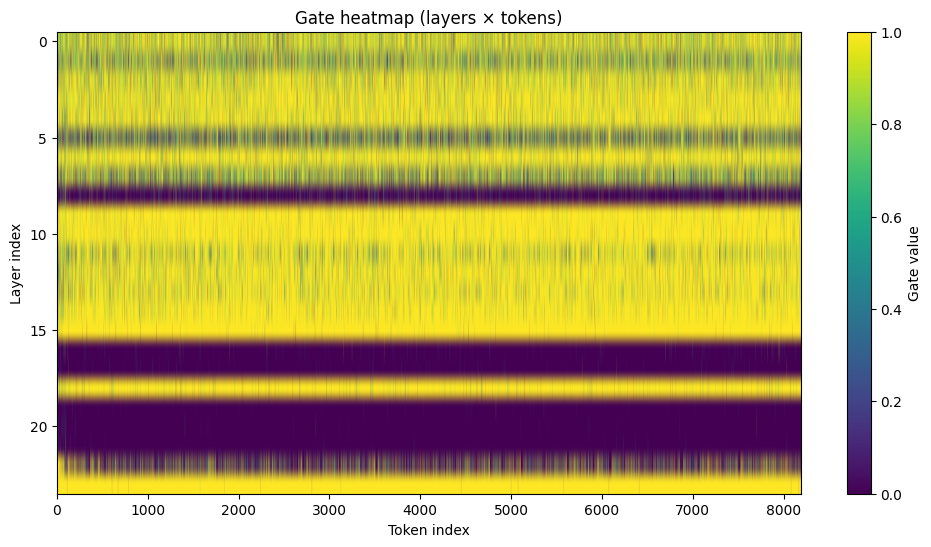

In [39]:
visualize_gate_heatmap(gate_store[:24])

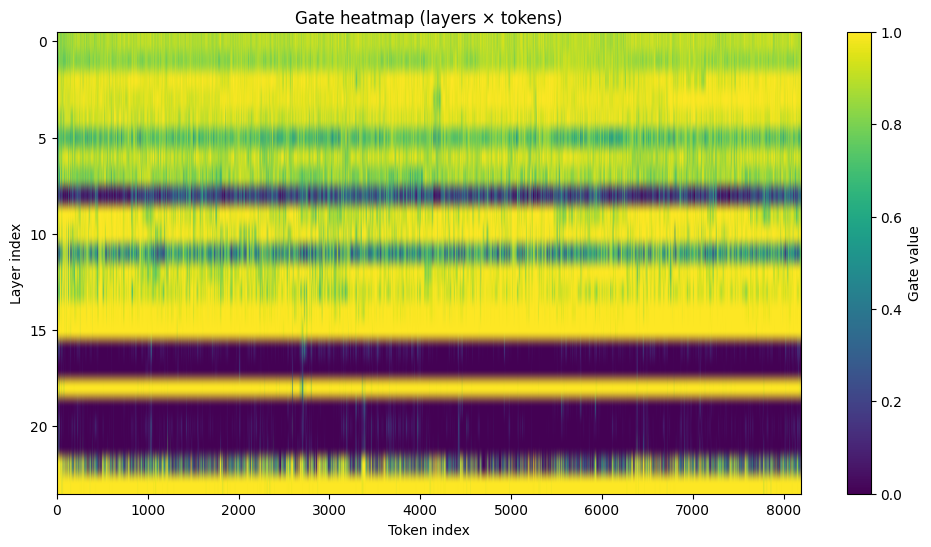

In [40]:
visualize_gate_heatmap(gate_store[-24:])

In [41]:
model.eval()
eval_ppl(model, wiki_testloader, device=DEV)

37.114967346191406

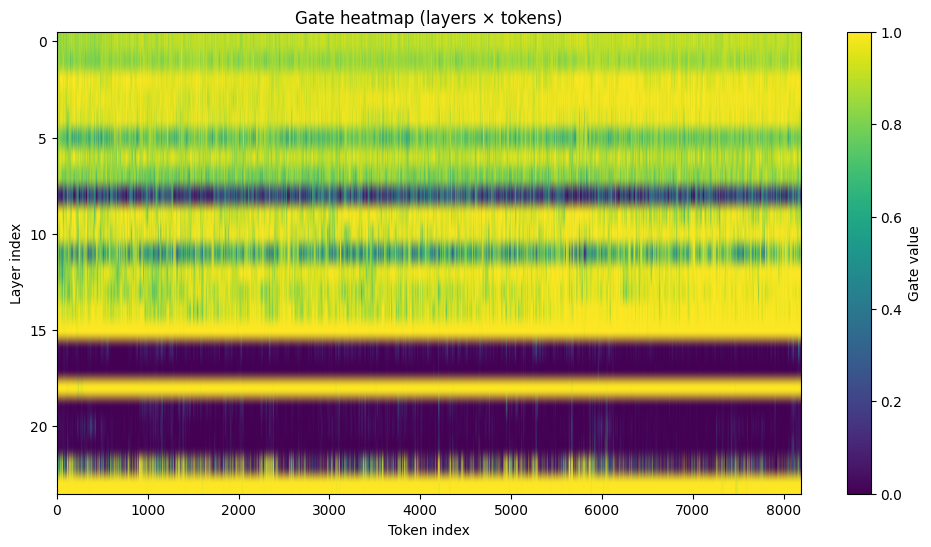

In [42]:
visualize_gate_heatmap(gate_store[-24:])

## Average weights and bias

<BarContainer object of 24 artists>

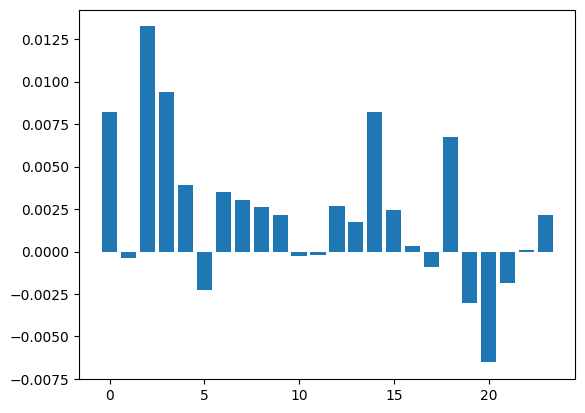

In [43]:
plt.bar(range(24), [model.model.layers[i].mlp.gate.proj.weight.mean().item() for i in range(24)])

<BarContainer object of 24 artists>

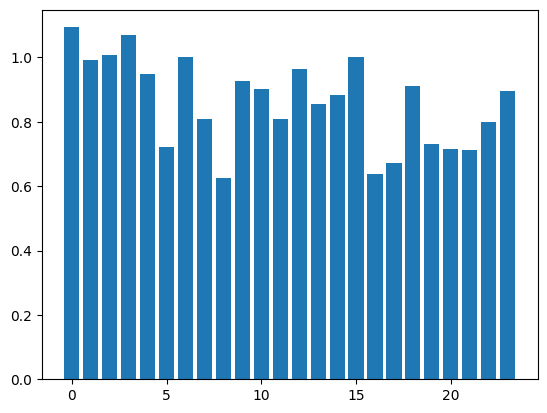

In [44]:
plt.bar(range(24), [model.model.layers[i].mlp.gate.proj.bias.item() for i in range(24)])

## Searching for optimal solution for individual samples

In [13]:
class TokenGate(nn.Module):
    def __init__(self, T, tau=1.0, gamma=-0.1, zeta=1.1, p_keep_init=0.7, jitter=0.01):
        super().__init__()
        init = math.log(p_keep_init / (1 - p_keep_init))
        log_alpha = init + jitter * torch.randn(1, T, 1, dtype=torch.bfloat16)
        self.log_alpha = nn.Parameter(log_alpha)
        # self.log_alpha = nn.Parameter(torch.zeros(1, T, 1))  # learnable per-token
        self.tau = tau
        self.gamma = gamma
        self.zeta = zeta

    def forward(self, h):
        B = h.shape[0]
        log_alpha = self.log_alpha.expand(B, -1, -1)

        if self.training:
            u = torch.rand_like(log_alpha).clamp_(1e-6, 1 - 1e-6)
            noise = torch.log(u) - torch.log1p(-u)
            s = torch.sigmoid((log_alpha + noise) / self.tau)
        else:
            # deterministic proxy
            s = torch.sigmoid(log_alpha)

        # stretch
        s_bar = s * (self.zeta - self.gamma) + self.gamma

        # clip
        z = torch.clamp(s_bar, 0.0, 1.0)

        return z, log_alpha

    # ---- expected L0 penalty (correct one from paper) ----
    def l0_penalty(self):
        log_ratio = -math.log(-self.gamma / self.zeta)
        prob_nonzero = torch.sigmoid(self.log_alpha - self.tau * log_ratio)
        return prob_nonzero.mean()

    # ---- optional: hard binary mask for analysis ----
    def hard_mask(self):
        with torch.no_grad():
            s = torch.sigmoid(self.log_alpha)
            s_bar = s * (self.zeta - self.gamma) + self.gamma
            return (s_bar > 0).float()

In [14]:
class GatedMLP(nn.Module):
    def __init__(self, mlp: nn.Module, T: int, gate_store: list, tau=1.0, gamma=-0.1, zeta=1.1):
        super().__init__()
        self.mlp = mlp
        self.gate = TokenGate(T, tau=tau, gamma=gamma, zeta=zeta)
        self.gate_store = gate_store  # store per-layer tensors for loss

    def forward(self, h):
        z, log_alpha = self.gate(h)   # z: [B,T,1]  log_alpha: [B,T,1]

        self.gate_store.append((z, log_alpha))

        mlp_out = self.mlp(h)         # [B,T,D]
        return z * mlp_out            # gated MLP output


In [15]:
def add_gates(model, gate_store, tau=1.0, gamma=-0.1, zeta=1.1):
    for layer in model.model.layers:
        layer.mlp = GatedMLP(layer.mlp, 8192, gate_store, tau=tau, gamma=gamma, zeta=zeta)

In [22]:
model = get_opt(model_name)
gate_store = []
add_gates(model, gate_store=gate_store)#, noise_scale=0.3, tau=0.3)
model.to(DEV)
model.train();

In [23]:
stats = {'ppl': [], 'val_ppl': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

# set_init_gate_weights(model, init_keep=0.7)
freeze_all_but_gates(model)

model, stats = train_gates(
    model=model,
    dataloader=dataloader[:1],
    gate_store=gate_store,
    stats=stats,
    device=DEV,
    epochs=10,
    lr=5e-3,
    target_skip=0.30,
    w_ratio=1e2,
    w_bin=0.5,
    log_every=1,
    eval_val_ppl=False,
    verbose=True
)
# model.eval();

epoch 0 step   1 tau 0.90 | lm_loss=7.48 | ppl=1767.74 | val_ppl=  0.00 | skip_ratio=0.05 | ratio_loss=25.38 | bin_loss=0.02 | total_loss=32.87
epoch 1 step   2 tau 0.90 | lm_loss=4.32 | ppl= 74.99 | val_ppl=  0.00 | skip_ratio=0.05 | ratio_loss=25.38 | bin_loss=0.02 | total_loss=29.71
epoch 2 step   3 tau 0.90 | lm_loss=4.15 | ppl= 63.41 | val_ppl=  0.00 | skip_ratio=0.05 | ratio_loss=25.38 | bin_loss=0.02 | total_loss=29.55
epoch 3 step   4 tau 0.90 | lm_loss=4.95 | ppl=141.84 | val_ppl=  0.00 | skip_ratio=0.05 | ratio_loss=25.38 | bin_loss=0.02 | total_loss=30.35
epoch 4 step   5 tau 0.90 | lm_loss=5.50 | ppl=244.70 | val_ppl=  0.00 | skip_ratio=0.05 | ratio_loss=25.38 | bin_loss=0.02 | total_loss=30.90
epoch 5 step   6 tau 0.90 | lm_loss=4.84 | ppl=126.92 | val_ppl=  0.00 | skip_ratio=0.05 | ratio_loss=25.38 | bin_loss=0.02 | total_loss=30.24
epoch 6 step   7 tau 0.90 | lm_loss=5.39 | ppl=218.48 | val_ppl=  0.00 | skip_ratio=0.05 | ratio_loss=25.38 | bin_loss=0.02 | total_loss=30.7

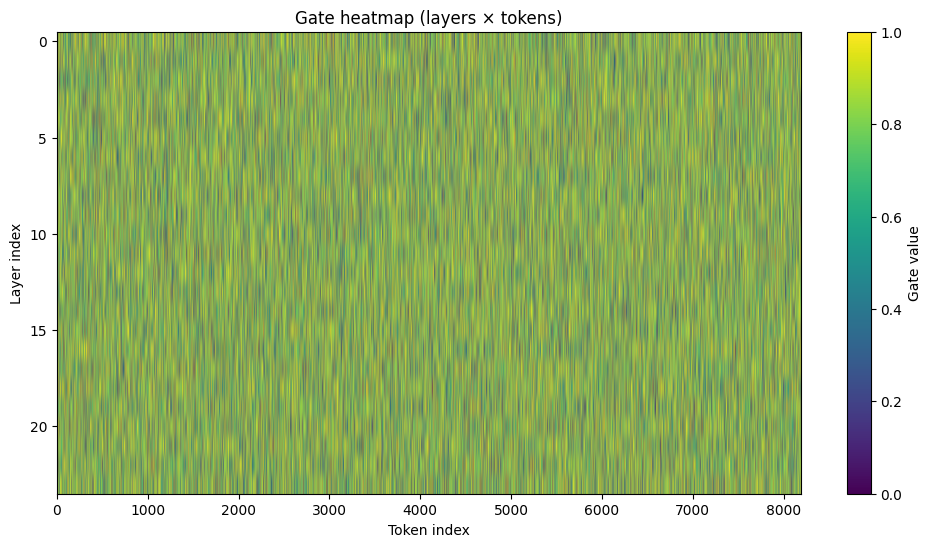

In [24]:
visualize_gate_heatmap(gate_store[-24:])